# U.S. happiness project
Question: **How are health, family income, marital status, age, and education associated with reported happiness among U.S. adults in 2024?** Associations are not proof of causes.

## Milestone 0: Dataset selection and audit
**Dataset:** NORC 2024 General Social Survey (GSS), release 3a, U.S. respondents. [Official data source](https://gss.norc.org/get-the-data/stata.html) and [codebook](https://gss.norc.org/content/dam/gss/get-documentation/pdf/codebook/GSS%202024%20Codebook%20R3a.pdf). Each row is one person's survey record. `dataset.csv` selects nine columns from the official GSS file, which contains many more questions.

**Data dictionary (all nine selected columns):**

| Column | Meaning |
| --- | --- |
| `id` | Unique respondent ID, not an explanatory variable |
| `happy` | General happiness: very happy, pretty happy, not too happy; outcome |
| `health` | Self-rated health: excellent, good, fair, poor |
| `income16` | Total family income last year before taxes, in 26 ordered brackets, not exact dollars |
| `marital` | Marital status |
| `age` | Age in years, or `89 or older` |
| `educ` | Years of schooling completed, exported as labels; not degrees |
| `amerstatus` | Whether the person is in the added AmeriSpeak sample |
| `wtssnrps_as` | Weight for the combined baseline and AmeriSpeak samples |

**Initial audit of `dataset.csv`:** 3,986 rows × 9 columns; 3,309 baseline and 677 additional respondents. Types: integer `id`, floating-point weight, seven text columns (including labeled age). Missing: `happy` 32, `health` 22, `income16` 423, `marital` 15, `age` 127, `educ` 34; other columns 0. Zero duplicate rows or IDs. Issues to handle: missing answers, age `89 or older` (28 cases), and income brackets rather than exact dollars. `INCOME16` is the name of a bracket version updated in **2016**, not income earned in 2016 or a count of 16 categories.

## Milestone 1: Documented cleaning decisions
The code below reads `dataset.csv` and saves a separate `cleaned_dataset.csv` with the same 3,986 rows and nine columns.

1. **Duplicates:** No duplicate rows or respondent IDs were found, so I removed no records.
2. **Missing answers:** I left unanswered values missing, not filled with guessed responses: `happy` 32 (0.8%), `health` 22 (0.6%), `marital` 15 (0.4%), `educ` 34 (0.9%), `age` 127 (3.2%), and `income16` 423 (10.6%). The answered labels in `happy`, `health`, and `marital` were consistent, so no categories were changed. Survey responses cannot safely be inferred; especially for income, nonresponse may not be random. Each later analysis should exclude only rows missing the variables it uses and report its sample size.
3. **Age:** Most ages were text-formatted numbers. I converted them to numeric, with `89 or older` coded as `89` for the 28 top-coded responses. This code means **89+**, not exactly 89; the 127 empty ages remain missing. There are enough reported ages for analysis without imputation. Exclude code 89 from any mean of *exact* ages and state that choice.
4. **Education:** I converted labeled grades to completed school years (`12th grade` → `12`; `2 years of college` → `14`; no formal schooling → `0`). The 165 answers `8 or more years of college` use code `20`, meaning **20+ years**, not exactly 20. The 34 unanswered values remain missing. This makes education sortable and numeric without inventing a degree or an exact value for the top group; exclude code 20 from any mean of *exact* schooling years.
5. **Income and sample design:** I kept the 26 valid `income16` bracket labels and their missing values unchanged: a bracket is not an exact dollar income. Brackets must be ordered by amount for later charts, not sorted alphabetically. I retained `amerstatus` and `wtssnrps_as` so later U.S. summaries can account for the additional AmeriSpeak sample. No weights were trimmed or imputed.

In [16]:
import pandas as pd

df = pd.read_csv('dataset.csv')

# EDUC uses years completed; code 20 means 20 or more, not exactly 20.
original_educ = df['educ'].copy()
grade = pd.to_numeric(original_educ.str.extract(r'^(\d+)(?:st|nd|rd|th) grade')[0])
college = pd.to_numeric(original_educ.str.extract(r'^(\d+) years? of college')[0])
df['educ'] = grade
df.loc[original_educ.eq('no formal schooling'), 'educ'] = 0
df.loc[college.notna(), 'educ'] = 12 + college[college.notna()]
df.loc[original_educ.eq('8 or more years of college'), 'educ'] = 20

# AGE code 89 means 89 or older; it is not an exact age.
original_age = df['age'].copy()
df['age'] = pd.to_numeric(original_age.replace({'89 or older': 89}), errors='coerce')
if (original_age.notna() & df['age'].isna()).any():
    raise ValueError('Inspect unexpected age values')
df.to_csv('cleaned_dataset.csv', index=False)
print('Saved cleaned_dataset.csv:', df.shape)

Saved cleaned_dataset.csv: (3986, 9)


### Descriptive statistics
Summarize exact ages (18–88) and schooling years (0–19) numerically; report the `89+` and `20+` groups separately because their exact values are unknown. For `happy`, `health`, `marital`, and income brackets, use response counts and percentages rather than numeric means. Percentages below are **unweighted sample descriptions among respondents who answered**, not U.S. population estimates.

In [17]:
import re

for column, top_code in [('age', 89), ('educ', 20)]:
    exact = df.loc[df[column] < top_code, column]
    print(f'\n{column}: exact values only (excludes {top_code}+):')
    print(exact.describe()[['count', 'mean', '50%', 'min', 'max', 'std']].round(2))
    print(f'{top_code}+ responses:', df[column].eq(top_code).sum(),
          '| missing:', df[column].isna().sum())

for column in ['happy', 'health', 'marital']:
    counts = df[column].value_counts()
    print(f'\n{column}: counts and percentages among answered (n={counts.sum()}):')
    print(pd.DataFrame({'count': counts,
                        'percent': (100 * counts / counts.sum()).round(1)}))
    print('Missing:', df[column].isna().sum())

income_order = sorted(df['income16'].dropna().unique(),
    key=lambda label: 0 if label == 'under $1,000' else
    int(re.search(r'\$([\d,]+)', label)[1].replace(',', '')))
income_counts = df['income16'].value_counts().reindex(income_order)
print(f'\nFamily income brackets (n={income_counts.sum()} answered):')
print(pd.DataFrame({'count': income_counts,
                    'percent': (100 * income_counts / income_counts.sum()).round(1)}))
print('Missing income:', df['income16'].isna().sum())


age: exact values only (excludes 89+):
count    3831.00
mean       48.74
50%        47.00
min        18.00
max        88.00
std        17.39
Name: age, dtype: float64
89+ responses: 28 | missing: 127

educ: exact values only (excludes 20+):
count    3787.00
mean       13.99
50%        14.00
min         0.00
max        19.00
std         2.72
Name: educ, dtype: float64
20+ responses: 165 | missing: 34

happy: counts and percentages among answered (n=3954):
               count  percent
happy                        
pretty happy    2303     58.2
not too happy    854     21.6
very happy       797     20.2
Missing: 32

health: counts and percentages among answered (n=3964):
           count  percent
health                   
good        2151     54.3
fair         975     24.6
excellent    665     16.8
poor         173      4.4
Missing: 22

marital: counts and percentages among answered (n=3971):
               count  percent
marital                      
married         1659     41.8
never

### Inferential analysis: Two chi-square tests
For each comparison, **H0:** the other variable and happiness are independent; **H1:** they are associated. Test (1) `health` versus `happy` and (2) `marital` versus `happy` at alpha = 0.05. Each unweighted contingency table uses respondents who answered **both** questions. Check expected cell counts and interpret association, not causation. The ordinary chi-square p-values do **not** account for the GSS survey's complex design or weights, so they are exploratory rather than survey-adjusted U.S. population inference.

In [18]:
from scipy.stats import chi2_contingency

for column in ['health', 'marital']:
    table = pd.crosstab(df[column], df['happy'])  # Missing answers excluded pairwise
    chi2, p, dof, expected = chi2_contingency(table)
    n = int(table.to_numpy().sum())
    cramers_v = (chi2 / (n * (min(table.shape) - 1))) ** 0.5
    print(f'\n{column} vs. happy (unweighted; n={n}):')
    print(table)
    print(f'Chi-square({dof})={chi2:.3f}, p={p:.3g}, '
          f'minimum expected={expected.min():.2f}, Cramers V={cramers_v:.3f}')
    print('Reject independence: an association is present in these responses.'
          if p < 0.05 else 'Do not reject independence: insufficient evidence of an association.')


health vs. happy (unweighted; n=3942):
happy      not too happy  pretty happy  very happy
health                                            
excellent             94           323         246
fair                 311           565          96
good                 360          1338         438
poor                  87            69          15
Chi-square(6)=338.884, p=3.75e-70, minimum expected=34.49, Cramers V=0.207
Reject independence: an association is present in these responses.

marital vs. happy (unweighted; n=3940):
happy          not too happy  pretty happy  very happy
marital                                               
divorced                 152           329          94
married                  209           965         473
never married            379           774         172
separated                 47            67          13
widowed                   64           160          42
Chi-square(8)=219.154, p=5.81e-43, minimum expected=25.59, Cramers V=0.167
Reject inde

**Interpretation (alpha = 0.05):** For health and happiness, 3,942 respondents answered both questions: chi-square(6) = **338.884**, p = **3.75 × 10^-70**, Cramer's V = **0.207**. Reject independence: the distribution of happiness responses differs across self-rated health groups. For marital status and happiness, 3,940 answered both: chi-square(8) = **219.154**, p = **5.81 × 10^-43**, Cramer's V = **0.167**. Reject independence: the distribution of happiness responses also differs across marital-status groups. These are **unweighted sample associations**, not proof that health or marriage causes happiness. Age, income, and other factors may differ between groups. The ordinary chi-square tests do not adjust for GSS sampling design; survey-design-aware methods would be needed for population-level inference.

## Milestone 2: Static visualization story
All five charts use `wtssnrps_as`: percentages are weighted within groups, and age summaries are weighted. Counts are unweighted eligible respondents. Missing answers and nonfinite or nonpositive weights are excluded per chart; empty groups have missing percentages. Estimates do not include survey-design uncertainty. Run the cell below to save five PNG files.

**Design rationale:** Grouped bars compare health and marital groups; lines compare income and schooling bands. The age boxplots use weighted inverse empirical-CDF quartiles: the smallest observed age whose cumulative weight reaches 25%, 50%, or 75%. Whiskers are the most extreme observed ages within 1.5 weighted IQRs of the quartiles; outliers are hidden. Age 89 is the top-coded 89+ group.

**Story:** Compare the weighted patterns across groups. Differences are associations, not evidence of causation.

**Accessibility:** A sequential blue palette (light = not too happy, medium = pretty happy, dark = very happy), thin outlines for contrast, consistent category order, readable labels, and legends help distinguish categories. Percentage axes start at zero; the box plot labels age in years.

**Bias critique:** Income nonresponse may change the pattern, and grouped brackets hide variation. Schooling categories span unequal ranges. Age code 89 means 89 or older, not an exact age. Weighting does not remove nonresponse bias; without survey-design uncertainty intervals, these are not precise population estimates or causal effects.

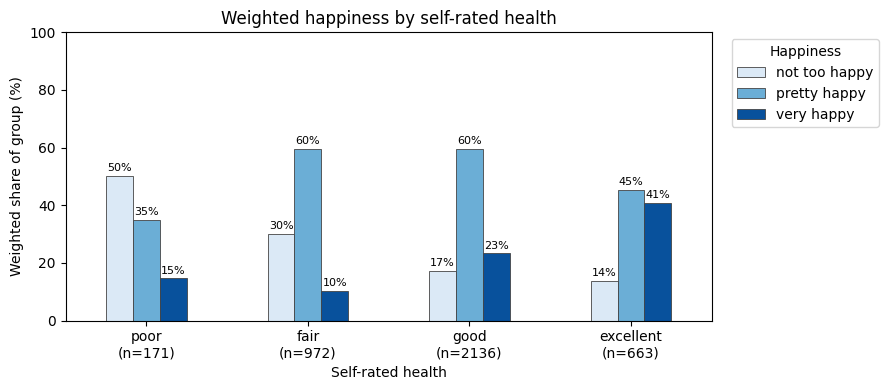

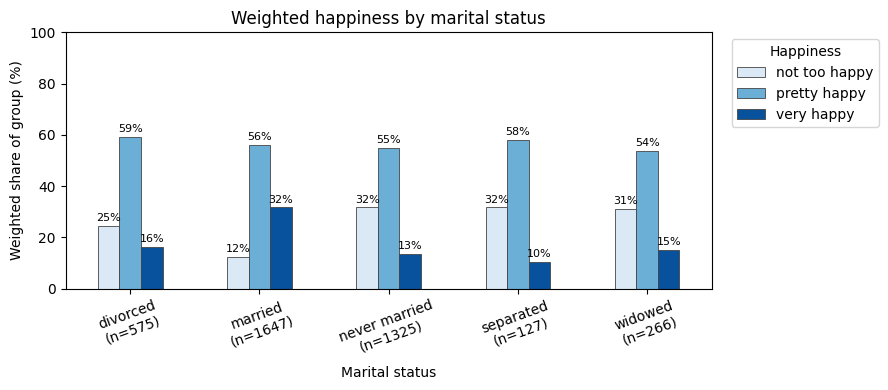

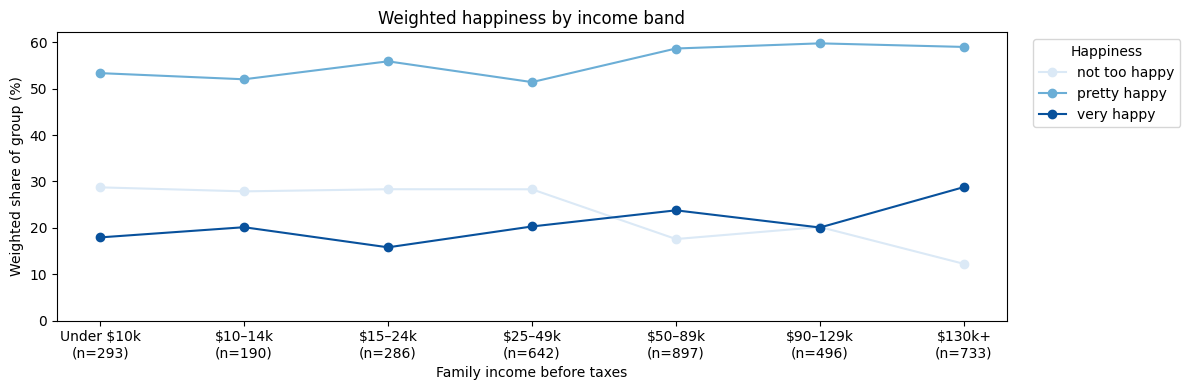

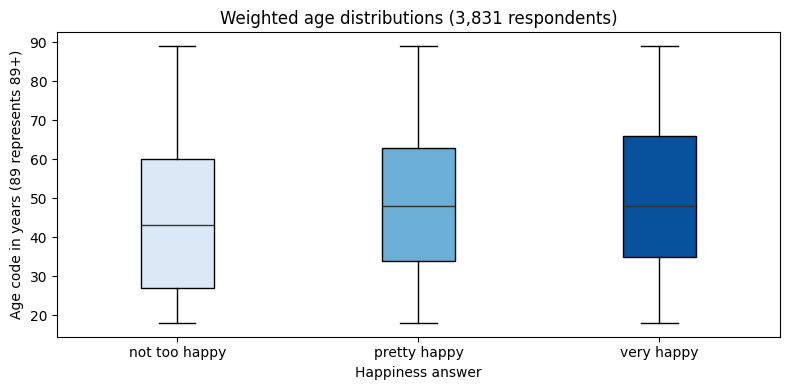

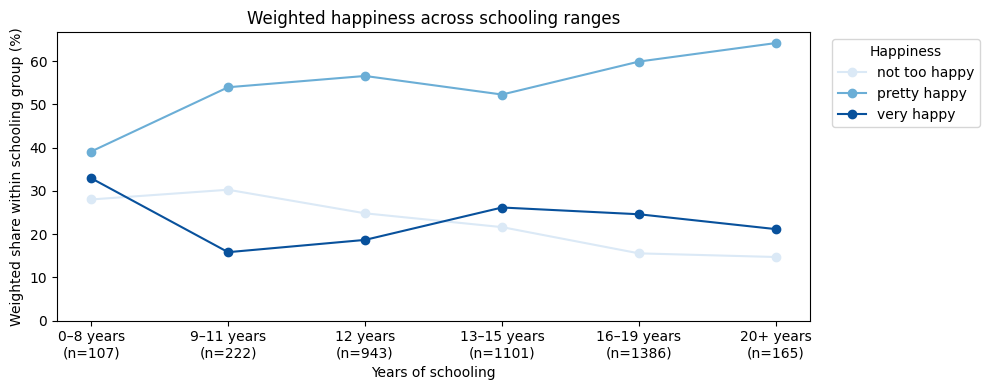

Saved five weighted charts; n denotes unweighted eligible respondents.


In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import re

viz = pd.read_csv('cleaned_dataset.csv')
happiness = ['not too happy', 'pretty happy', 'very happy']
colors = ['#DBE9F6', '#6BAED6', '#08519C']
def eligible(frame, *columns):
    weight = pd.to_numeric(frame['wtssnrps_as'], errors='coerce')
    valid = frame.loc[frame[list(columns)].notna().all(axis=1) & np.isfinite(weight) & weight.gt(0)].copy()
    valid['wtssnrps_as'] = weight.loc[valid.index]
    return valid

def weighted_shares(frame, group, groups):
    valid = eligible(frame, group, 'happy')
    counts = pd.crosstab(valid[group], valid.happy).reindex(index=groups, columns=happiness, fill_value=0)
    weights = valid.groupby([group, 'happy'], observed=True)['wtssnrps_as'].sum().unstack(fill_value=0).reindex(index=groups, columns=happiness, fill_value=0)
    return weights.div(weights.sum(axis=1).replace(0, np.nan), axis=0).mul(100), counts

def age_summary(frame, answer):
    valid = eligible(frame, 'age', 'happy')
    valid = valid.loc[valid.happy.eq(answer) & valid.age.between(18, 89)].sort_values('age')
    if valid.empty:
        return None
    ages = valid.age.to_numpy()
    cumulative = valid.wtssnrps_as.to_numpy().cumsum()
    q1, median, q3 = ages[np.searchsorted(cumulative, cumulative[-1] * np.array([.25, .5, .75]))]
    iqr = q3 - q1
    inside = ages[(ages >= q1 - 1.5 * iqr) & (ages <= q3 + 1.5 * iqr)]
    return dict(label=answer, q1=q1, med=median, q3=q3, whislo=inside.min(), whishi=inside.max(), n=len(valid))

def percentages(group):
    groups = viz[group].cat.categories if isinstance(viz[group].dtype, pd.CategoricalDtype) else sorted(viz[group].dropna().unique())
    return weighted_shares(viz, group, groups)[0]

# 1. Distribution of happiness within each health group.
fig, ax = plt.subplots(figsize=(9, 4))
health_rates = percentages('health').reindex(['poor', 'fair', 'good', 'excellent'])
health_rates.plot.bar(color=colors, edgecolor='#444444', linewidth=0.6, ax=ax)
health_n = weighted_shares(viz, 'health', health_rates.index)[1].sum(axis=1)
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.0f%%', padding=2, fontsize=8)
ax.set_xticklabels([f'{g}\n(n={health_n[g]})' for g in health_rates.index], rotation=0)
ax.set(title='Weighted happiness by self-rated health',
       xlabel='Self-rated health', ylabel='Weighted share of group (%)', ylim=(0, 100))
ax.legend(title='Happiness', loc='upper left', bbox_to_anchor=(1.02, 1))
fig.tight_layout(); fig.savefig('milestone2_1_health.png', dpi=200, bbox_inches='tight'); plt.show()

# 2. Compare within-group percentages, retaining group sizes for context.
fig, ax = plt.subplots(figsize=(9, 4))
marital_rates = percentages('marital')
marital_rates.plot.bar(color=colors, edgecolor='#444444', linewidth=0.6, ax=ax)
marital_n = weighted_shares(viz, 'marital', marital_rates.index)[1].sum(axis=1)
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.0f%%', padding=2, fontsize=8)
ax.set_xticklabels([f'{g}\n(n={marital_n[g]})' for g in marital_rates.index])
ax.set(title='Weighted happiness by marital status', xlabel='Marital status',
       ylabel='Weighted share of group (%)', ylim=(0, 100))
ax.legend(title='Happiness', loc='upper left', bbox_to_anchor=(1.02, 1))
plt.xticks(rotation=20); fig.tight_layout()
fig.savefig('milestone2_2_marital.png', dpi=200, bbox_inches='tight'); plt.show()

# 3. Combine ordered income brackets without inventing exact income.
income_order = sorted(viz.income16.dropna().unique(), key=lambda s:
    0 if s == 'under $1,000' else int(re.search(r'\$([\d,]+)', s)[1].replace(',', '')))
viz['income_band'] = pd.cut(viz.income16.map({v: i for i, v in enumerate(income_order, 1)}),
    [0, 8, 10, 14, 18, 21, 23, 26],
    labels=['Under $10k', '$10–14k', '$15–24k', '$25–49k', '$50–89k', '$90–129k', '$130k+'])
income_rates = percentages('income_band')
fig, ax = plt.subplots(figsize=(12, 4))
income_rates.plot.line(color=colors, marker='o', ax=ax)
income_n = weighted_shares(viz, 'income_band', income_rates.index)[1].sum(axis=1)
ax.set_xticks(range(len(income_rates)),
              [f'{g}\n(n={income_n[g]})' for g in income_rates.index])
ax.set(title='Weighted happiness by income band', xlabel='Family income before taxes',
       ylabel='Weighted share of group (%)')
ax.set_ylim(bottom=0)
ax.legend(title='Happiness', loc='upper left', bbox_to_anchor=(1.02, 1))
plt.xticks(rotation=0); fig.tight_layout()
fig.savefig('milestone2_3_income.png', dpi=200, bbox_inches='tight'); plt.show()

# 4. Include 89+ using the recorded code 89; label it as top-coded.
age_stats = [age_summary(viz, h) for h in happiness]
fig, ax = plt.subplots(figsize=(8, 4))
boxes = ax.bxp([s for s in age_stats if s is not None], showfliers=False, patch_artist=True,
               medianprops={'color': '#333333'})
for box, color in zip(boxes['boxes'], colors):
    box.set_facecolor(color)
ax.set(title=f'Weighted age distributions ({sum(s["n"] for s in age_stats if s):,} respondents)',
       xlabel='Happiness answer', ylabel='Age code in years (89 represents 89+)')
fig.tight_layout(); fig.savefig('milestone2_4_age.png', dpi=200); plt.show()

# 5. Compare happiness answers within six schooling-year ranges.
viz['school_band'] = pd.cut(viz.educ, [-1, 8, 11, 12, 15, 19, 20],
    labels=['0–8 years', '9–11 years', '12 years',
            '13–15 years', '16–19 years', '20+ years'])
school = percentages('school_band')
school_n = weighted_shares(viz, 'school_band', school.index)[1].sum(axis=1)
fig, ax = plt.subplots(figsize=(10, 4))
school.plot.line(color=colors, marker='o', ax=ax)
ax.set_xticks(range(len(school)),
              [f'{g}\n(n={school_n[g]})' for g in school.index])
ax.set(title='Weighted happiness across schooling ranges',
       xlabel='Years of schooling', ylabel='Weighted share within schooling group (%)')
ax.set_ylim(bottom=0)
ax.legend(title='Happiness', loc='upper left', bbox_to_anchor=(1.02, 1))
fig.tight_layout(); fig.savefig('milestone2_5_education.png', dpi=200); plt.show()
print('Saved five weighted charts; n denotes unweighted eligible respondents.')

## Milestone 3: Interactive dashboard prototype
**Question and interaction:** A marital-status filter updates weighted health, age, and income views. Hover reports unweighted eligible respondent counts and weighted percentages. Age boxes use the same weighted quartiles and whiskers defined in Milestone 2, with 89 representing 89+. Empty groups have missing percentages. Estimates use `wtssnrps_as` but have no survey-design uncertainty intervals.

**Peer feedback: pending.** No classmate has tested the dashboard yet. Ask a peer to select `Marital status: widowed`, describe what changes in all three views, and explain the income chart. Then ask them to return to `All respondents`. Record their actual feedback and any revision.

In [20]:
import pandas as pd
import re
import plotly.graph_objects as go
from plotly.subplots import make_subplots

data = pd.read_csv('cleaned_dataset.csv')
answers = ['not too happy', 'pretty happy', 'very happy']
health_order = ['poor', 'fair', 'good', 'excellent']
colors = ['#DBE9F6', '#6BAED6', '#08519C']
income_order = sorted(data.income16.dropna().unique(), key=lambda s:
    0 if s == 'under $1,000' else int(re.search(r'\$([\d,]+)', s)[1].replace(',', '')))
income_rank = data.income16.map({v: i for i, v in enumerate(income_order, 1)})
data['income_band'] = pd.cut(income_rank, [0, 8, 10, 14, 18, 21, 23, 26],
    labels=['Under $10k', '$10–14k', '$15–24k', '$25–49k',
            '$50–89k', '$90–129k', '$130k+'])

filters = [('All respondents', data)]
filters += [(f'Marital status: {s}', data[data.marital.eq(s)])
            for s in ['married', 'never married', 'divorced', 'widowed', 'separated']]

dashboard = make_subplots(rows=3, cols=1, vertical_spacing=0.13,
    row_heights=[0.36, 0.30, 0.34],
    subplot_titles=('Happiness responses within health groups',
                    'Age distributions within happiness groups',
                    'Happiness responses across income bands'))

for label, subset in filters:
    shares, counts = weighted_shares(subset, 'health', health_order)
    for answer, color in zip(answers, colors):
        dashboard.add_trace(go.Bar(
            x=health_order, y=shares[answer], name=answer,
            customdata=counts[answer], marker_color=color,
            marker_line_color='#444444', marker_line_width=0.5,
            hovertemplate=(f'Health: %{{x}}<br>Happiness: {answer}'
                           '<br>Unweighted respondents: %{customdata}'
                           '<br>Weighted within-group share: %{y:.1f}%<extra></extra>'),
            visible=(label == 'All respondents'),
            showlegend=(label == 'All respondents'),
        ), row=1, col=1)
    for answer, color in zip(answers, colors):
        stats = age_summary(subset, answer)
        dashboard.add_trace(go.Box(
            x=[answer], q1=[stats['q1'] if stats else None], median=[stats['med'] if stats else None],
            q3=[stats['q3'] if stats else None], lowerfence=[stats['whislo'] if stats else None],
            upperfence=[stats['whishi'] if stats else None], name=answer, fillcolor=color, line_color='#333333',
            customdata=[[stats['n'] if stats else 0]],
            hovertemplate=(f'Happiness: {answer}<br>Unweighted respondents: %{{customdata[0]}}'
                           '<br>Weighted Q1: %{q1}<br>Weighted median: %{median}<br>Weighted Q3: %{q3}'
                           '<br>Lower whisker: %{lowerfence}<br>Upper whisker: %{upperfence}<extra></extra>'),
            boxpoints=False, visible=(label == 'All respondents'), showlegend=False,
        ), row=2, col=1)
    income_shares, income_counts = weighted_shares(subset, 'income_band', data.income_band.cat.categories)
    for answer, color in zip(answers, colors):
        dashboard.add_trace(go.Scatter(
            x=income_shares.index.astype(str), y=income_shares[answer],
            name=answer, mode='lines+markers', line=dict(color=color),
            marker=dict(size=8), customdata=income_counts[answer],
            hovertemplate=(f'Income: %{{x}}<br>Happiness: {answer}'
                           '<br>Unweighted respondents: %{customdata}'
                           '<br>Weighted within-income share: %{y:.1f}%<extra></extra>'),
            visible=(label == 'All respondents'), showlegend=False,
        ), row=3, col=1)

buttons = []
for index, (label, _) in enumerate(filters):
    buttons.append(dict(label=label, method='update',
        args=[{'visible': [i // 9 == index for i in range(len(dashboard.data))]},
              {'title': f'2024 GSS Weighted Happiness Dashboard | {label}'}]))
dashboard.update_layout(
    title='2024 GSS Weighted Happiness Dashboard | All respondents',
    barmode='stack', template='plotly_white', height=1050,
    legend=dict(orientation='h', x=0, y=1.08),
    margin=dict(t=140, l=75, r=35, b=60),
    updatemenus=[dict(buttons=buttons, direction='down',
                      x=1, xanchor='right', y=1.16, yanchor='top')],
)
dashboard.update_xaxes(title_text='Self-rated health', row=1, col=1)
dashboard.update_yaxes(title_text='Weighted share of health group (%)', range=[0, 100],
                       row=1, col=1)
dashboard.update_xaxes(title_text='Happiness answer', row=2, col=1)
dashboard.update_yaxes(title_text='Age code in years (89 represents 89+)', range=[18, 90],
                       row=2, col=1)
dashboard.update_xaxes(title_text='Family income band', row=3, col=1)
dashboard.update_yaxes(title_text='Weighted share of income group (%)', rangemode='tozero',
                       row=3, col=1)
dashboard.write_html('milestone3_dashboard.html', include_plotlyjs=True,
                     full_html=True, config={'displaylogo': False, 'responsive': True})
print('Saved milestone3_dashboard.html with three charts and a marital filter')

Saved milestone3_dashboard.html with three charts and a marital filter
